<a href="https://colab.research.google.com/github/Carmen10-171/07MIAR_Redes-Neuronales/blob/main/07MIAR_Proyecto_redes_neuronales_grupo_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto de Programación: Deep Vision in Classification Tasks
**Asignatura:** 07MIAR - Redes Neuronales y Deep Learning  
**Dataset:** Plant Seedlings Classification  
**Grupo:** Grupo 1 (Juan José, Raúl Medina, Alfredo González, Mª Carmen Copé Soler)

---
## Pipeline de Trabajo Completo
1. **Carga del conjunto de datos**: Conexión y descarga/acceso a la carpeta base `BASE_FOLDER`.
2. **Inspección del conjunto de datos**: Exploración de clases, balance de muestras y visualización.
3. **Acondicionamiento del conjunto de datos**: Normalización, particionado (80/20) y optimización del flujo con `tf.data`.
4. **Estrategia 1 (Entrenar desde cero / From Scratch)**: Diseño, regularización iterativa (Data Augmentation, Batch Normalization, Dropout, L2 Regularization, Callbacks).
5. **Estrategia 2 (Red Pre-entrenada / Transfer Learning & Fine-Tuning)**: Comparación entre al menos dos arquitecturas pre-entrenadas en ImageNet (MobileNetV2 vs ResNet50), selección empírica de la mejor y ajuste fino (Fine-Tuning).
6. **Monitorización, Evaluación y Comparativa Final**: Gráficos de entrenamiento/validación, tablas resumen, matrices de confusión y conclusiones justificadas.

## 1. Carga del Conjunto de Datos
En esta sección definimos el directorio base (`BASE_FOLDER`), cargamos la estructura de archivos y preparamos los conjuntos de datos para entrenamiento y validación.

In [ ]:
import os
import tensorflow as tf

# Directorio Base
BASE_FOLDER = r"C:\Users\ccope\OneDrive\Documents\plant-seedlings-classification"
train_path = os.path.join(BASE_FOLDER, "train")
test_path = os.path.join(BASE_FOLDER, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("Contenido del directorio base:", os.listdir(BASE_FOLDER))

# Carga del conjunto de datos de entrenamiento (80%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Carga del conjunto de datos de validación (20%)
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print("\nClases disponibles:", class_names)
print(f"Número total de clases: {len(class_names)}")

Contenido del directorio base: ['sample_submission.csv', 'test', 'train']
Found 4750 files belonging to 12 classes.
Using 3800 files for training.
Found 4750 files belonging to 12 classes.
Using 950 files for validation.

Clases disponibles: ['Black-grass', 'Charlock', 'Cleavers', 'Common Chickweed', 'Common wheat', 'Fat Hen', 'Loose Silky-bent', 'Maize', 'Scentless Mayweed', 'Shepherds Purse', 'Small-flowered Cranesbill', 'Sugar beet']
Número total de clases: 12


## 2. Inspección del Conjunto de Datos
Analizamos la cantidad de imágenes disponibles por cada especie botánica y mostramos ejemplos representativos.

                        Clase  Numero_imagenes
6            Loose Silky-bent              654
3            Common Chickweed              611
8           Scentless Mayweed              516
10  Small-flowered Cranesbill              496
5                     Fat Hen              475
1                    Charlock              390
11                 Sugar beet              385
2                    Cleavers              287
0                 Black-grass              263
9             Shepherds Purse              231
7                       Maize              221
4                Common wheat              221


C:\Users\ccope\AppData\Local\Temp\ipykernel_52252\92796491.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_counts, x="Clase", y="Numero_imagenes", palette="viridis")


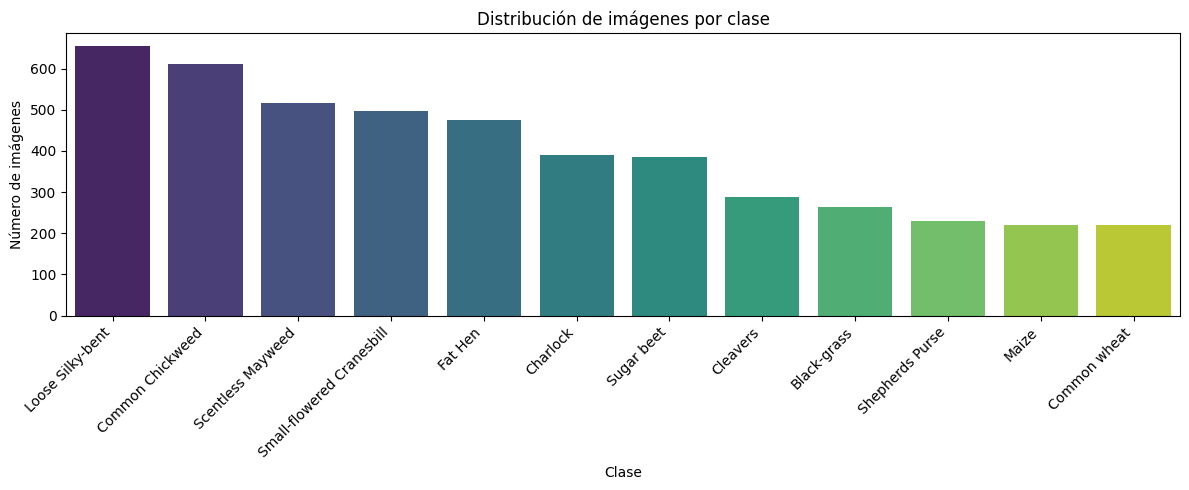

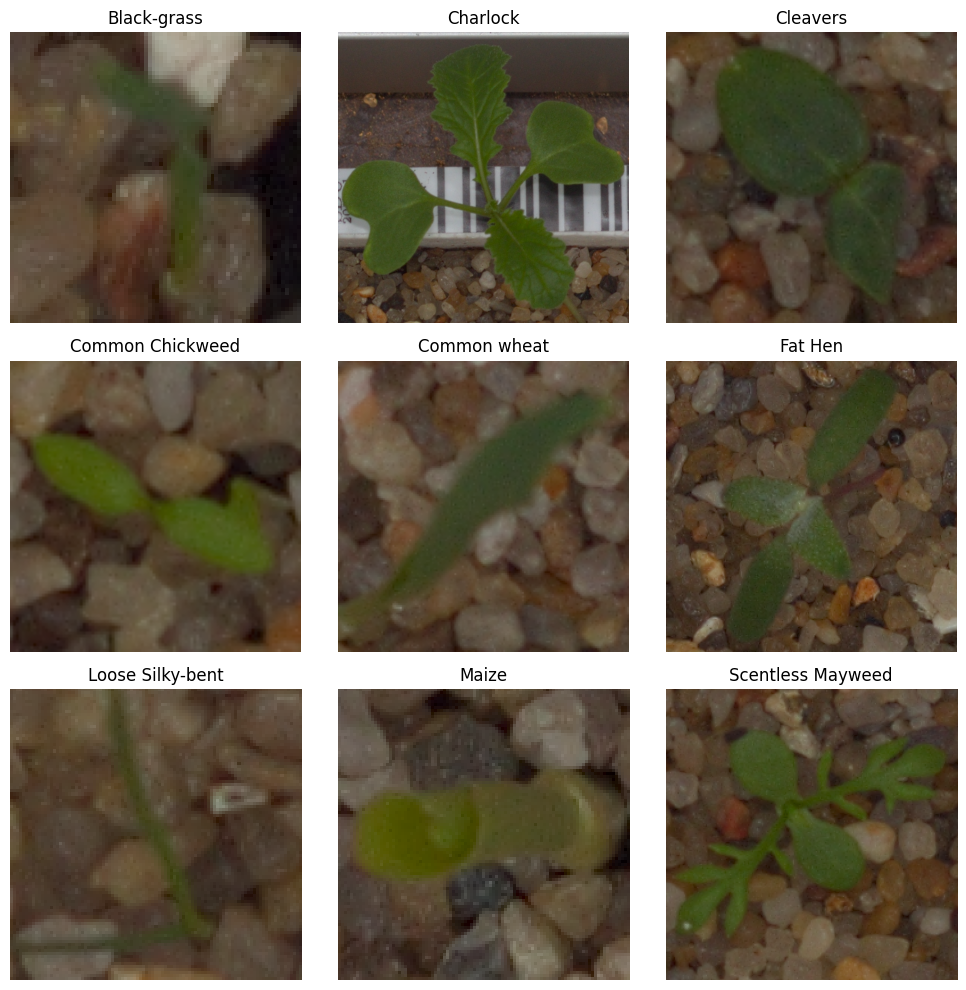

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import numpy as np

# Recuento de muestras por clase
class_counts = {}
for clase in os.listdir(train_path):
    ruta_clase = os.path.join(train_path, clase)
    if os.path.isdir(ruta_clase):
        class_counts[clase] = len(os.listdir(ruta_clase))

df_counts = pd.DataFrame(list(class_counts.items()), columns=["Clase", "Numero_imagenes"])
df_counts = df_counts.sort_values(by="Numero_imagenes", ascending=False)
print(df_counts)

# Gráfica de distribución de clases
plt.figure(figsize=(12, 5))
sns.barplot(data=df_counts, x="Clase", y="Numero_imagenes", palette="viridis")
plt.xticks(rotation=45, ha='right')
plt.title("Distribución de imágenes por clase")
plt.ylabel("Número de imágenes")
plt.tight_layout()
plt.show()

# Visualización de imágenes representativas
plt.figure(figsize=(10, 10))
for i, clase in enumerate(sorted(os.listdir(train_path))[:9]):
    carpeta = os.path.join(train_path, clase)
    imagen_nombre = np.random.choice(os.listdir(carpeta))
    ruta_img = os.path.join(carpeta, imagen_nombre)
    img = cv2.imread(ruta_img)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(clase)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 3. Acondicionamiento del Conjunto de Datos
Aplicamos la normalización del rango dinámico $[0, 1]$ mediante `Rescaling` y preparamos el pipeline optimizado con `cache()` y `prefetch()` para acelerar el procesamiento en aceleradores de hardware (GPU/TPU).

In [ ]:
from tensorflow.keras import layers

# Normalización [0, 1]
normalization_layer = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

# Optimización de pipeline tf.data
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# Callbacks transversales para todos los experimentos
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1
)

---
## 4. Estrategia 1: Entrenar desde cero (From Scratch)
Diseñamos una arquitectura profunda de Red Neuronal Convolucional (CNN) propia y justificamos empíricamente la adición progresiva de técnicas de regularización:
* **Experimento 1**: CNN Base (línea de partida sin regularizadores).
* **Experimento 2**: Adición de Data Augmentation para incrementar la variabilidad sintética.
* **Experimento 3**: Adición de Batch Normalization para estabilizar las activaciones internas.
* **Experimento 4**: Adición de Dropout para romper co-adaptaciones complejas de neuronas.
* **Experimento 5**: Adición de Regularización L2 (Weight Regularization / Decay) para penalizar pesos excesivamente grandes.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, BatchNormalization, Activation, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import regularizers

# ==============================================================================
# Experimento 1: CNN Base (Baseline)
# ==============================================================================
print("--- Experimento 1: CNN Base ---")
cnn_base = Sequential([
    layers.Input(shape=(224, 224, 3)),
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(len(class_names), activation='softmax')
], name="CNN_Base")

cnn_base.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_base = cnn_base.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=[early_stop, reduce_lr])
loss_base, acc_base = cnn_base.evaluate(val_ds, verbose=0)
print(f"Accuracy CNN Base: {acc_base:.4f}\n")

# ==============================================================================
# Bloque de Data Augmentation
# ==============================================================================
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1)
], name="Data_Augmentation")

# ==============================================================================
# Experimento 2: CNN + Data Augmentation
# ==============================================================================
print("--- Experimento 2: Data Augmentation ---")
cnn_aug = Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(),
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(len(class_names), activation='softmax')
], name="CNN_Augmentation")

cnn_aug.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_aug = cnn_aug.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=[early_stop, reduce_lr])
loss_aug, acc_aug = cnn_aug.evaluate(val_ds, verbose=0)
print(f"Accuracy CNN + Augmentation: {acc_aug:.4f}\n")

# ==============================================================================
# Experimento 3: CNN + Batch Normalization
# ==============================================================================
print("--- Experimento 3: Batch Normalization ---")
cnn_bn = Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    Conv2D(32, (3, 3), padding='same'), BatchNormalization(), Activation('relu'), MaxPooling2D(),
    Conv2D(64, (3, 3), padding='same'), BatchNormalization(), Activation('relu'), MaxPooling2D(),
    Conv2D(128, (3, 3), padding='same'), BatchNormalization(), Activation('relu'), MaxPooling2D(),
    Flatten(), Dense(128, activation='relu'), Dense(len(class_names), activation='softmax')
], name="CNN_BatchNorm")

cnn_bn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_bn = cnn_bn.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=[early_stop, reduce_lr])
loss_bn, acc_bn = cnn_bn.evaluate(val_ds, verbose=0)
print(f"Accuracy CNN + BatchNorm: {acc_bn:.4f}\n")

# ==============================================================================
# Experimento 4: CNN + Dropout
# ==============================================================================
print("--- Experimento 4: Dropout ---")
cnn_dropout = Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    Conv2D(32, (3, 3), padding='same'), BatchNormalization(), Activation('relu'), MaxPooling2D(),
    Conv2D(64, (3, 3), padding='same'), BatchNormalization(), Activation('relu'), MaxPooling2D(),
    Conv2D(128, (3, 3), padding='same'), BatchNormalization(), Activation('relu'), MaxPooling2D(),
    Flatten(), Dense(128, activation='relu'), Dropout(0.5), Dense(len(class_names), activation='softmax')
], name="CNN_Dropout")

cnn_dropout.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_dropout = cnn_dropout.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=[early_stop, reduce_lr])
loss_dropout, acc_dropout = cnn_dropout.evaluate(val_ds, verbose=0)
print(f"Accuracy CNN + Dropout: {acc_dropout:.4f}\n")

# ==============================================================================
# Experimento 5: CNN + Weight Regularization L2 (Modelo Final Scratch)
# ==============================================================================
print("--- Experimento 5: Regularización L2 (Modelo Final Scratch) ---")
l2_reg = regularizers.l2(0.001)
cnn_l2 = Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    Conv2D(32, (3, 3), padding='same', kernel_regularizer=l2_reg), BatchNormalization(), Activation('relu'), MaxPooling2D(),
    Conv2D(64, (3, 3), padding='same', kernel_regularizer=l2_reg), BatchNormalization(), Activation('relu'), MaxPooling2D(),
    Conv2D(128, (3, 3), padding='same', kernel_regularizer=l2_reg), BatchNormalization(), Activation('relu'), MaxPooling2D(),
    Flatten(), Dense(128, activation='relu', kernel_regularizer=l2_reg), Dropout(0.5), Dense(len(class_names), activation='softmax')
], name="CNN_L2_Final")

cnn_l2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_l2 = cnn_l2.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=[early_stop, reduce_lr])
loss_l2, acc_l2 = cnn_l2.evaluate(val_ds, verbose=0)
print(f"Accuracy CNN + Regularización L2: {acc_l2:.4f}\n")

--- Experimento 1: CNN Base ---
Epoch 1/5


C:\Users\ccope\miniconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 294s 2s/step - accuracy: 0.1413 - loss: 2.4640 - val_accuracy: 0.1453 - val_loss: 2.4055 - learning_rate: 0.0010
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 294s 2s/step - accuracy: 0.3518 - loss: 1.9228 - val_accuracy: 0.4874 - val_loss: 1.4551 - learning_rate: 0.0010
Epoch 3/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 229s 2s/step - accuracy: 0.6158 - loss: 1.1188 - val_accuracy: 0.5884 - val_loss: 1.2187 - learning_rate: 0.0010
Epoch 5/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 208s 2s/step - accuracy: 0.7021 - loss: 0.8711 - val_accuracy: 0.6495 - val_loss: 1.0754 - learning_rate: 0.0010
Accuracy CNN Base: 0.6495

--- Experimento 2: Data Augmentation ---
Epoch 1/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 234s 2s/step - accuracy: 0.1750 - loss: 2.4038 - val_accuracy: 0.3568 - val_loss: 1.9479 - learning_rate: 0.0010
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 226s 2s/step - accuracy: 0.4011 - loss: 1.7318 - val_accuracy: 0.4411 - val_loss: 1.5421 - learning_rate: 0.0010
Epoch 3/5
119/119 ━━━━━━━━━━━━

---
## 5. Estrategia 2: Red pre-entrenada (Transfer Learning y Fine-Tuning)
En esta segunda estrategia evaluamos y comparamos dos arquitecturas emblemáticas pre-entrenadas con la base de datos ImageNet (`MobileNetV2` y `ResNet50`).
1. **Experimento 6 (MobileNetV2)**: Extracción de características con congelación del bloque convolucional base.
2. **Experimento 7 (ResNet50)**: Extracción de características con congelación del bloque convolucional base en arquitectura residual.
3. **Experimento 8 (Fine-Tuning)**: Selección automática de la arquitectura con mayor rendimiento en validación y descongelación de sus últimas 30 capas superiores con una tasa de aprendizaje reducida (`1e-5`).

In [ ]:
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras import Model

# ==============================================================================
# Experimento 6: MobileNetV2 (Feature Extractor)
# ==============================================================================
print("--- Experimento 6: MobileNetV2 ---")
base_mobilenet = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_mobilenet.trainable = False

inputs_mob = layers.Input(shape=(224, 224, 3))
x = data_augmentation(inputs_mob)
x = base_mobilenet(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs_mob = layers.Dense(len(class_names), activation='softmax')(x)

mobilenet_model = Model(inputs_mob, outputs_mob, name="MobileNetV2_Model")
mobilenet_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_mobilenet = mobilenet_model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=[early_stop, reduce_lr])
loss_mobile, acc_mobile = mobilenet_model.evaluate(val_ds, verbose=0)
print(f"Accuracy MobileNetV2: {acc_mobile:.4f}\n")

# ==============================================================================
# Experimento 7: ResNet50 (Feature Extractor)
# ==============================================================================
print("--- Experimento 7: ResNet50 ---")
base_resnet = ResNet50(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_resnet.trainable = False

inputs_res = layers.Input(shape=(224, 224, 3))
x = data_augmentation(inputs_res)
x = base_resnet(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001))(x)
x = layers.Dropout(0.5)(x)
outputs_res = layers.Dense(len(class_names), activation='softmax')(x)

resnet_model = Model(inputs_res, outputs_res, name="ResNet50_Model")
resnet_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_resnet = resnet_model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=[early_stop, reduce_lr])
loss_resnet, acc_resnet = resnet_model.evaluate(val_ds, verbose=0)
print(f"Accuracy ResNet50: {acc_resnet:.4f}\n")

# ==============================================================================
# Experimento 8: Selección Automática y Fine-Tuning del Modelo Ganador
# ==============================================================================
print("--- Experimento 8: Fine-Tuning ---")
if acc_resnet > acc_mobile:
    best_model = resnet_model
    best_base_model = base_resnet
    best_name = "ResNet50"
    best_acc_init = acc_resnet
else:
    best_model = mobilenet_model
    best_base_model = base_mobilenet
    best_name = "MobileNetV2"
    best_acc_init = acc_mobile

print(f"Modelo seleccionado automáticamente para Fine-Tuning: {best_name} (Accuracy inicial: {best_acc_init:.4f})")

# Descongelación parcial (últimas 30 capas)
best_base_model.trainable = True
for layer in best_base_model.layers[:-30]:
    layer.trainable = False

best_model.compile(optimizer=Adam(learning_rate=1e-5), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_finetune = best_model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=[early_stop, reduce_lr])
loss_finetune, acc_finetune = best_model.evaluate(val_ds, verbose=0)
print(f"Accuracy final tras Fine-Tuning ({best_name}): {acc_finetune:.4f}\n")

--- Experimento 6: MobileNetV2 ---
Epoch 1/5


C:\Users\ccope\miniconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 123s 986ms/step - accuracy: 0.4518 - loss: 1.7802 - val_accuracy: 0.5968 - val_loss: 1.2572 - learning_rate: 0.0010
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.6250 - loss: 1.1459 - val_accuracy: 0.6253 - val_loss: 1.1109 - learning_rate: 0.0010
Epoch 3/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.6721 - loss: 1.0039 - val_accuracy: 0.6516 - val_loss: 1.0053 - learning_rate: 0.0010
Epoch 4/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 164s 1s/step - accuracy: 0.6926 - loss: 0.9070 - val_accuracy: 0.6768 - val_loss: 0.9243 - learning_rate: 0.0010
Epoch 5/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.7161 - loss: 0.8540 - val_accuracy: 0.6958 - val_loss: 0.8985 - learning_rate: 0.0010
Accuracy MobileNetV2: 0.6958

--- Experimento 7: ResNet50 ---
Epoch 1/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 530s 4s/step - accuracy: 0.1703 - loss: 2.5792 - val_accuracy: 0.1189 - val_loss: 2.6001 - learning_rate: 0.0010
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━

---
## 6. Monitorización, Evaluación y Comparativa Final
Comparamos la eficacia de los 8 modelos desarrollados mediante DataFrames resumen, gráficos de barras de precisión, reporte detallado de clasificación y matriz de confusión del modelo ganador.

=== TABLA COMPARATIVA FINAL DE RENDIMIENTO ===
                      Modelo  Accuracy
0  MobileNetV2 + Fine-Tuning  0.732632
1                MobileNetV2  0.695789
2                   CNN Base  0.649474
3         CNN + Augmentation  0.643158
4                   ResNet50  0.270526
5            CNN + BatchNorm  0.176842
6              CNN + Dropout  0.144211
7                   CNN + L2  0.144211


C:\Users\ccope\AppData\Local\Temp\ipykernel_52252\3989176745.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_final, x="Modelo", y="Accuracy", palette="viridis")


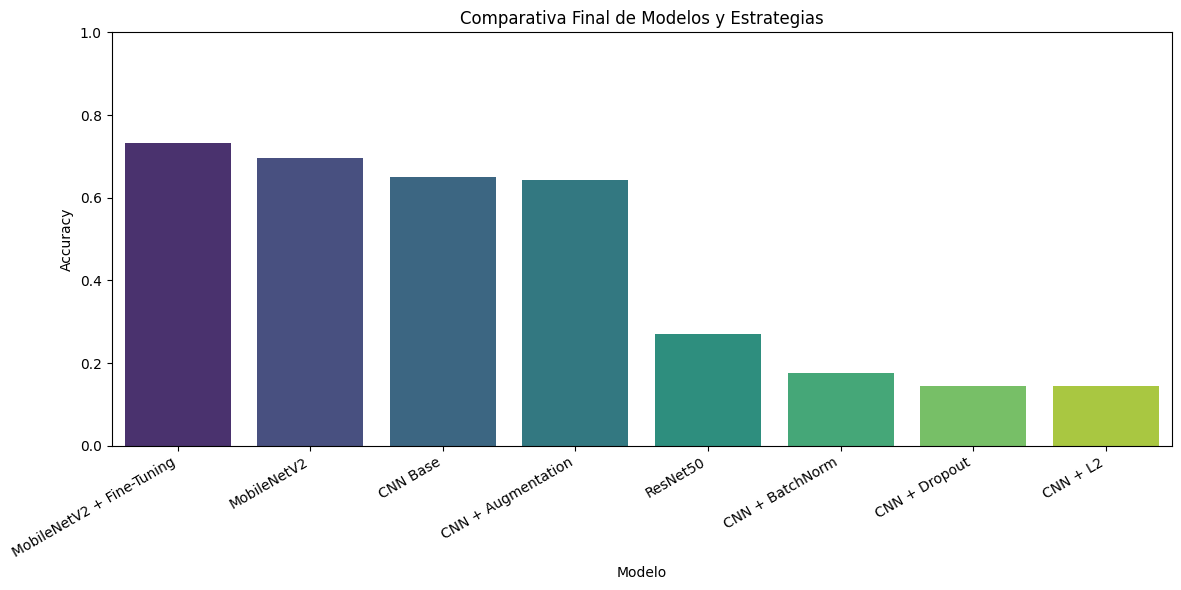

30/30 ━━━━━━━━━━━━━━━━━━━━ 22s 618ms/step

--- Classification Report Final (MobileNetV2 + Fine-Tuning) ---
                           precision    recall  f1-score   support

              Black-grass       0.56      0.34      0.42        53
                 Charlock       0.88      0.92      0.90        61
                 Cleavers       0.66      0.86      0.74        56
         Common Chickweed       0.81      0.79      0.80       111
             Common wheat       0.72      0.63      0.67        49
                  Fat Hen       0.90      0.66      0.76       111
         Loose Silky-bent       0.73      0.76      0.74       137
                    Maize       0.89      0.64      0.75        53
        Scentless Mayweed       0.71      0.59      0.65       106
          Shepherds Purse       0.41      0.70      0.51        43
Small-flowered Cranesbill       0.86      0.90      0.88       106
               Sugar beet       0.59      0.88      0.70        64

                 acc

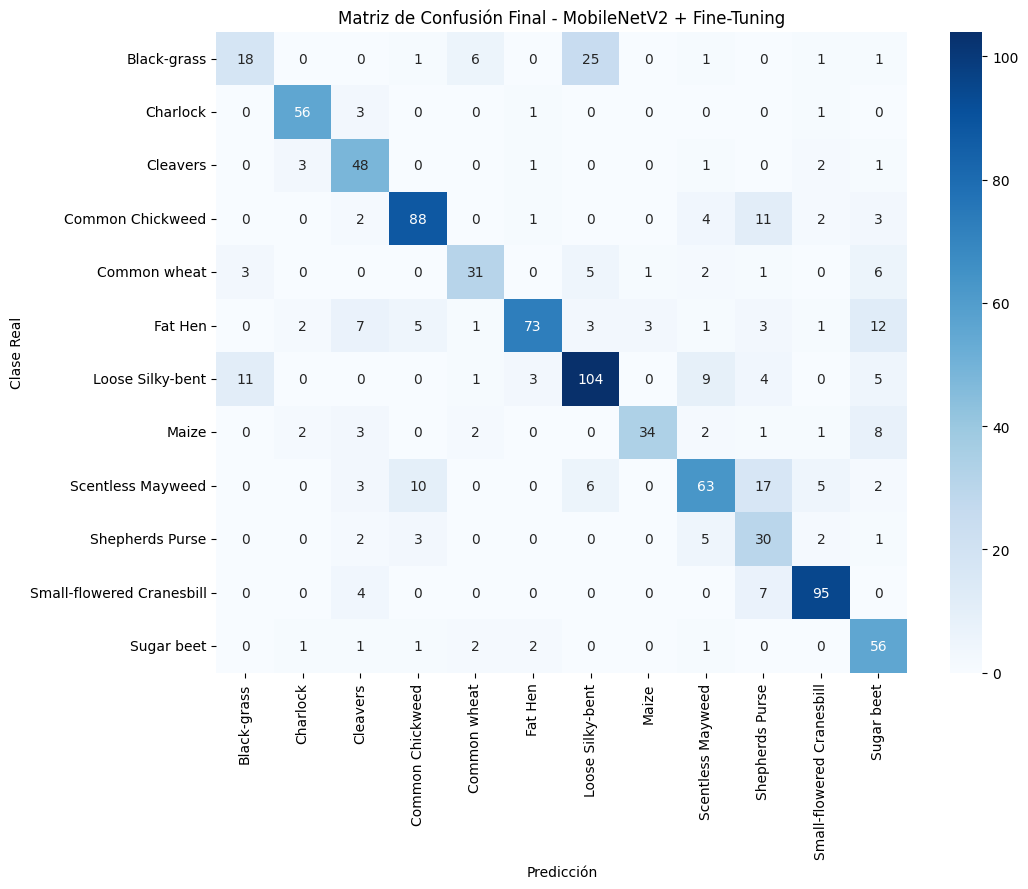

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Dataframe comparativo de todos los modelos
results_final = pd.DataFrame({
    "Modelo": [
        "CNN Base",
        "CNN + Augmentation",
        "CNN + BatchNorm",
        "CNN + Dropout",
        "CNN + L2",
        "MobileNetV2",
        "ResNet50",
        f"{best_name} + Fine-Tuning"
    ],
    "Accuracy": [
        acc_base,
        acc_aug,
        acc_bn,
        acc_dropout,
        acc_l2,
        acc_mobile,
        acc_resnet,
        acc_finetune
    ]
})

results_final = results_final.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)
print("=== TABLA COMPARATIVA FINAL DE RENDIMIENTO ===")
print(results_final)

# Visualización comparativa global
plt.figure(figsize=(12, 6))
sns.barplot(data=results_final, x="Modelo", y="Accuracy", palette="viridis")
plt.xticks(rotation=30, ha='right')
plt.title("Comparativa Final de Modelos y Estrategias")
plt.ylim(0, 1.0)
plt.tight_layout()
plt.show()

# Predicciones del modelo optimizado
y_true = np.concatenate([y.numpy() for x, y in val_ds], axis=0)
y_pred_final = np.argmax(best_model.predict(val_ds), axis=1)

print(f"\n--- Classification Report Final ({best_name} + Fine-Tuning) ---")
print(classification_report(y_true, y_pred_final, target_names=class_names))

# Matriz de confusión final
cm_final = confusion_matrix(y_true, y_pred_final)
plt.figure(figsize=(11, 9))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f"Matriz de Confusión Final - {best_name} + Fine-Tuning")
plt.xlabel("Predicción")
plt.ylabel("Clase Real")
plt.tight_layout()
plt.show()